In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 16
    }
)

In [3]:
fname_mutants = "../experiment_results.csv"
fname_wt_summary = "../Group_I_Intron/WT_summary.csv"
fname_matching_data = "../Group_I_Intron/Matching_Data.csv"
fname_structure = "../Group_I_Intron/dot-bracket-structure.txt"

df_mutants = pd.read_csv(fname_mutants)
df_matching_data = pd.read_csv(fname_matching_data)
df_wt_summary = pd.read_csv(fname_wt_summary)

with open(fname_structure, "r") as f:
    structure = f.read().strip()
    structure = structure.replace("[", "(").replace("]", ")")
    
print(df_wt_summary.head())

  WT name            old name  Activity @ 37C  Activity @ 60C  \
0    wt_1  dca_f_sequenza_682           -1.57             NaN   
1    wt_2  dca_f_sequenza_689           -1.23             NaN   
2    wt_3  dca_f_sequenza_698           -1.87             NaN   
3    wt_4  dca_f_sequenza_707           -1.58             NaN   
4    wt_5  dca_f_sequenza_739           -1.94             NaN   

   distance from Azo  SB score  
0                 25       NaN  
1                 25       NaN  
2                 25       NaN  
3                 25       NaN  
4                 25       NaN  


In [4]:
from adabmDCA import get_tokens, encode_sequence

Wild type sequence: GUGAUUUUCGCCGGGAGUCCCCGUAAGGAAUGGUGUCAAAUUCGGCGAAACCUAAACGACCGAAAGGUCGUAUGGCAACGCCGAGCCAAGCUUUGGUAGAAAUGUCAUUGAAGGUGUAGAGACUAGACGGCACCCACCUAAGGCAAUCUCUAUGGUGAAGGCAUAGUCCAGAGAGUGACGAAAGUCACACAUACCGG
Region: highDCA_highSB, Number of mutants: 50, Number of top mutants: 12
Region: lowDCA_lowSB, Number of mutants: 50, Number of top mutants: 12
Region: lowDCA_highSB, Number of mutants: 150, Number of top mutants: 37


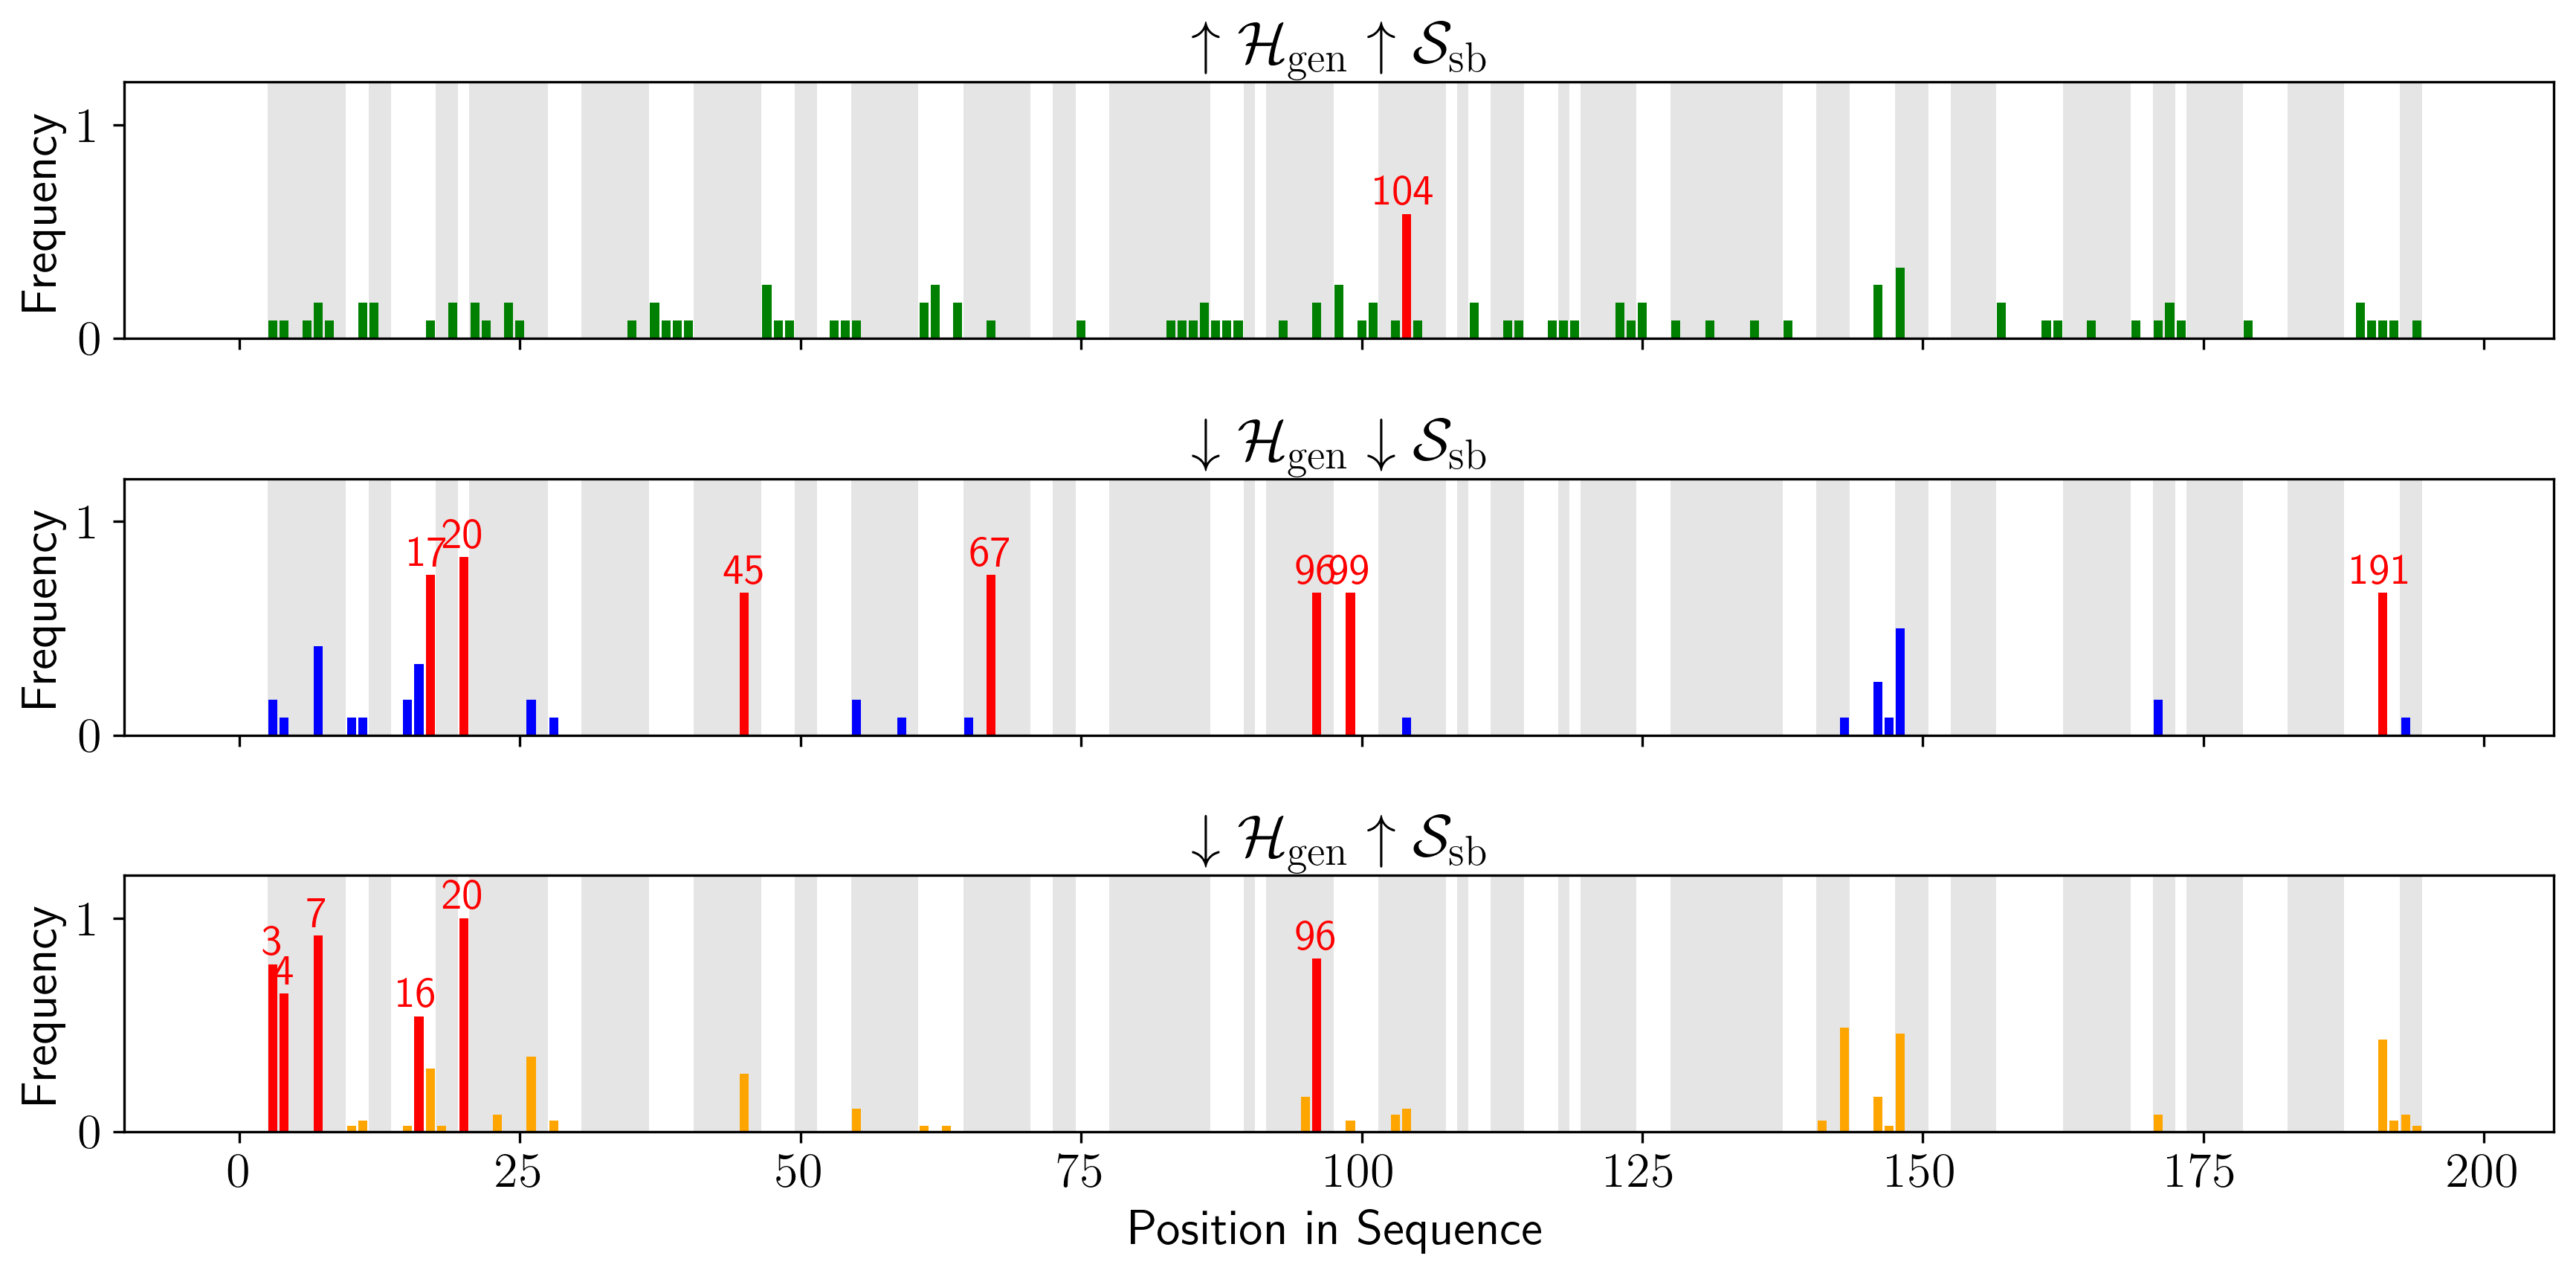

In [58]:
wild_type_id = "wt_7"
threshold = 0.5  # Define a threshold for highlighting positions

old_wt_name = df_wt_summary[df_wt_summary["WT name"] == wild_type_id]["old name"].values[0]
wt_sequence = df_matching_data[df_matching_data["names"] == old_wt_name]["sequences"].values[0]
print(f"Wild type sequence: {wt_sequence}")
df_wt = df_mutants[(df_mutants["wt_id"] == float(wild_type_id.split("_")[1]))]

tokens = get_tokens("rna")
encoded_wt = encode_sequence(wt_sequence, tokens)

regions = ["highDCA_highSB", "lowDCA_lowSB", "lowDCA_highSB"]
region_to_title = {
    "highDCA_highSB": r"$\uparrow \mathcal{H}_{\mathrm{gen}} \uparrow \mathcal{S}_{\mathrm{sb}}$",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}} \uparrow \mathcal{S}_{\mathrm{sb}}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_{\mathrm{gen}} \downarrow \mathcal{S}_{\mathrm{sb}}$"
}
region_to_color = {
    "highDCA_highSB": "green",
    "lowDCA_highSB": "orange",
    "lowDCA_lowSB": "blue",
}
region_to_threshold = {
    "highDCA_highSB": 0.5,
    "lowDCA_highSB": 0.5,
    "lowDCA_lowSB": 0.5
}

fig, ax = plt.subplots(3, 1, figsize=(12, 6), dpi=300, sharex=True)
for i, region in enumerate(regions):
    df_region = df_wt[df_wt["region"] == region]
    # determine ntop as the number of mutants in the top 25% of the activity distribution in the region
    n_top = int(0.25 * len(df_region))
    print(f"Region: {region}, Number of mutants: {len(df_region)}, Number of top mutants: {n_top}")
    top_mutants = df_region.sort_values(by="activity_60", ascending=False).head(n_top)
    encoded_top_mutants = encode_sequence(top_mutants["seq"].values, tokens)
    mutations_top = encoded_top_mutants != encoded_wt
    with open(f"../color_codes/color_code_forna_{wild_type_id}_{region}.txt", "w") as f:
        for mut_freq in np.mean(mutations_top, axis=0):
            f.write(f"{mut_freq} ")
    mutation_frequency_top = np.mean(mutations_top, axis=0)
    
    # Add grey shaded areas for base-paired regions
    for pos, char in enumerate(structure):
        if char in ['(', ')', '[', ']']:
            ax[i].axvspan(pos - 0.5, pos + 0.5, color='grey', alpha=0.2, zorder=0, linewidth=0)
    
    # Highlight positions with frequency above threshold
    positions_above_threshold = np.where(mutation_frequency_top > region_to_threshold[region])[0]
    ax[i].bar(range(0, len(mutation_frequency_top)), mutation_frequency_top, color=region_to_color[region])
    ax[i].bar(positions_above_threshold, mutation_frequency_top[positions_above_threshold], color="red", alpha=1.0)
    for pos in positions_above_threshold:
        ax[i].text(pos, mutation_frequency_top[pos], str(pos), ha='center', va='bottom', fontsize=14, color='red')
    
    ax[i].set_ylabel("Frequency")
    ax[i].set_title(region_to_title[region])
    ax[i].set_ylim(0, 1.2)
ax[2].set_xlabel("Position in Sequence")
plt.tight_layout()
plt.show()

In [59]:
top_mutant = top_mutants["seq"].values[0]
print(top_mutant)

GUGCUUUACGCCGGGAGUUCGCGUAAAGAAUGGUGUCAAAUUCGGUGAAACCUAAACGACCGAAAGGUCGUAUGGCAACGCCGAGCCAAGCUUUGGCAGAAAUGCCAUUGAAGGUGUAGAGACUAGACGGCACCCACCUAAGGCAAUCGCUAUGGUGAAGGCAUAGUCCAGAGAGUGACGAAAGUCACACAAACCGG


In [60]:
# function that, given a position, returns the pair of connected positions in the structure
def get_paired_positions(idx, structure):
    stack = []
    paired = {}
    for i, char in enumerate(structure):
        if char == '(':
            stack.append(i)
        elif char == ')':
            j = stack.pop()
            paired[i] = j
            paired[j] = i
    return paired.get(idx, None)

mutant_idx = 0
region = "lowDCA_highSB"
df_region = df_wt[df_wt["region"] == region]
top_mutants = df_region.sort_values(by="activity_60", ascending=False).head(n_top)

position = 133
match = get_paired_positions(position, structure)
if match is not None:
    print(f"Contact: {position}-{match}")
    print(f"WT: {wt_sequence[position]}-{wt_sequence[match]}")
    print(f"Mutant: {top_mutants.iloc[mutant_idx]['seq'][position]}-{top_mutants.iloc[mutant_idx]['seq'][match]}")
else:
    print(f"Position {position} is not paired in the structure.")

Contact: 133-118
WT: C-G
Mutant: C-G


### Study the singular mutations and their effect for specific wild-types

In [61]:
wild_type_id = "wt_7"
region = "lowDCA_highSB"
top_mutant_idx = 0

old_wt_name = df_wt_summary[df_wt_summary["WT name"] == wild_type_id]["old name"].values[0]
wt_sequence = df_matching_data[df_matching_data["names"] == old_wt_name]["sequences"].values[0]
df_wt = df_mutants[(df_mutants["wt_id"] == float(wild_type_id.split("_")[1]))]
df_region = df_wt[df_wt["region"] == region]
top_mutant = df_region.sort_values(by="activity_60", ascending=False).iloc[top_mutant_idx]["seq"]

mutations = []
mutations_reversed = []
for pos in range(len(wt_sequence)):
    if wt_sequence[pos] != top_mutant[pos]:
        print(f"Position {pos+1}: WT={wt_sequence[pos]}, Mutant={top_mutant[pos]}")
        mutations.append(f"{wt_sequence[pos]}_{pos}_{top_mutant[pos]}")
        mutations_reversed.append(f"{top_mutant[pos]}_{pos}_{wt_sequence[pos]}")
print("\n(Positions are counted from 1)")

Position 4: WT=A, Mutant=C
Position 8: WT=U, Mutant=A
Position 19: WT=C, Mutant=U
Position 21: WT=C, Mutant=G
Position 27: WT=G, Mutant=A
Position 46: WT=C, Mutant=U
Position 97: WT=U, Mutant=C
Position 105: WT=U, Mutant=C
Position 149: WT=U, Mutant=G
Position 192: WT=U, Mutant=A

(Positions are counted from 1)


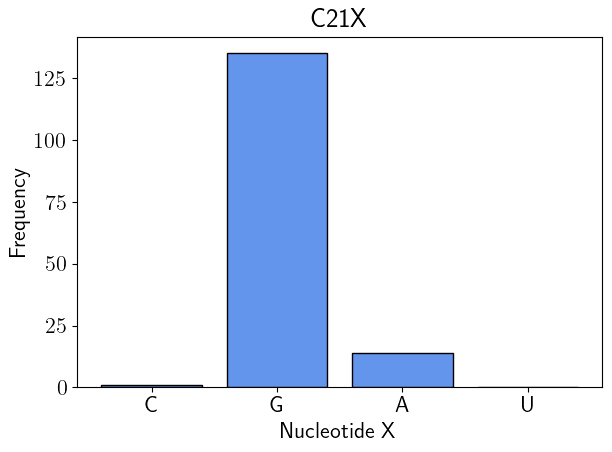

In [62]:
# Focus on a specific position and plot a barplot with the frequency of mutations at that position across all mutants in the region
pos = 21 - 1
mutation_freq_at_pos = {"C": 0, "G": 0, "A": 0, "U": 0}
for mutant_seq in df_region["seq"].values:
    if mutant_seq[pos] in mutation_freq_at_pos:
        mutation_freq_at_pos[mutant_seq[pos]] += 1
plt.bar(mutation_freq_at_pos.keys(), mutation_freq_at_pos.values(), color="cornflowerblue", edgecolor="black")
plt.xlabel("Nucleotide X")
plt.ylabel("Frequency")
plt.title(f"{wt_sequence[pos]}{pos + 1}X")
plt.tight_layout()
plt.show()

In [63]:
import torch
device = torch.device("mps")
dtype = torch.float32

tokens = "ACGU-"
path_model = "../modello_FC_T=1"
params_file = np.load(path_model, allow_pickle=True)

params = {
    "bias": torch.tensor(params_file["h_local"], dtype=dtype, device=device).contiguous(),
    "coupling_matrix": torch.tensor(params_file["couplings"], dtype=dtype, device=device),
}

In [64]:
from adabmDCA import compute_energy
from rna_utils import compute_bpp_scores, calculate_free_energies

def compute_delta_scores(context, mutations, params, tokens, fe="sb"):
    context_enc = encode_sequence(context, tokens)[3:-1]  # Remove start and end tokens
    context_pt = torch.tensor(context_enc, dtype=torch.long, device=device)
    context_pt = torch.nn.functional.one_hot(context_pt, num_classes=len(tokens)).float().unsqueeze(0)
    energy_context = compute_energy(context_pt, params)
    if fe == "sb":
        sb_context = compute_bpp_scores([context], structure, 1)[0]
    elif fe == "fe":
        sb_context = calculate_free_energies([context], structure, 60)[0]
    else:
        raise ValueError("Invalid fe value. Use 'sb' or 'fe'.")
    
    wt_residues = [mut.split("_")[0] for mut in mutations]
    positions = [int(mut.split("_")[1]) for mut in mutations] # Adjust for start token
    mut_residues = [mut.split("_")[2] for mut in mutations]
    
    delta_scores = {}
    contact_pairs = []
    for i, pos in enumerate(positions):
        contact = get_paired_positions(pos, structure)
        contact = contact if contact in positions else None
        mutant = context[:pos] + mut_residues[i] + context[pos+1:]
        mutant_enc = encode_sequence(mutant, tokens)[3:-1]  # Remove start and end tokens
        mutant_pt = torch.tensor(mutant_enc, dtype=torch.long, device=device)
        mutant_pt = torch.nn.functional.one_hot(mutant_pt, num_classes=len(tokens)).float().unsqueeze(0)
        energy_mutant = compute_energy(mutant_pt, params)
        delta_energy = energy_mutant - energy_context
        if fe == "sb":
            sb_mut = compute_bpp_scores([mutant], structure, 1)[0]
        elif fe == "fe":
            sb_mut = calculate_free_energies([mutant], structure, 60)[0]
        else:
            raise ValueError("Invalid fe value. Use 'sb' or 'fe'.")
        delta_sb = sb_mut - sb_context
        delta_scores[f"{wt_residues[i]}_{pos + 1}_{mut_residues[i]}"] = {"dca": delta_energy.item(), "sb": delta_sb}
        # mutate both positions and compute energy difference
        if contact is not None:
            if (pos, contact) in contact_pairs or (contact, pos) in contact_pairs:
                continue  # Skip if this pair has already been mutated
            mutant = context[:pos] + mut_residues[i] + context[pos+1:]
            i_contact = positions.index(contact)
            mutant = mutant[:contact] + mut_residues[i_contact] + mutant[contact+1:]
            mutant_enc = encode_sequence(mutant, tokens)[3:-1]  # Remove start and end tokens
            mutant_pt = torch.tensor(mutant_enc, dtype=torch.long, device=device)
            mutant_pt = torch.nn.functional.one_hot(mutant_pt, num_classes=len(tokens)).float().unsqueeze(0)
            energy_mutant = compute_energy(mutant_pt, params)
            delta_energy = energy_mutant - energy_context
            if fe == "sb":
                sb_mut = compute_bpp_scores([mutant], structure, 1)[0]
            elif fe == "fe":
                sb_mut = calculate_free_energies([mutant], structure, 60)[0]
            else:
                raise ValueError("Invalid fe value. Use 'sb' or 'fe'.")
            delta_sb = sb_mut - sb_context
            delta_scores[f"{wt_residues[i]}_{pos + 1}_{mut_residues[i]}+{wt_residues[i_contact]}_{contact + 1}_{mut_residues[i_contact]}"] = {"dca": delta_energy.item(), "sb": delta_sb}
            contact_pairs.append((pos, contact))
    
    return delta_scores

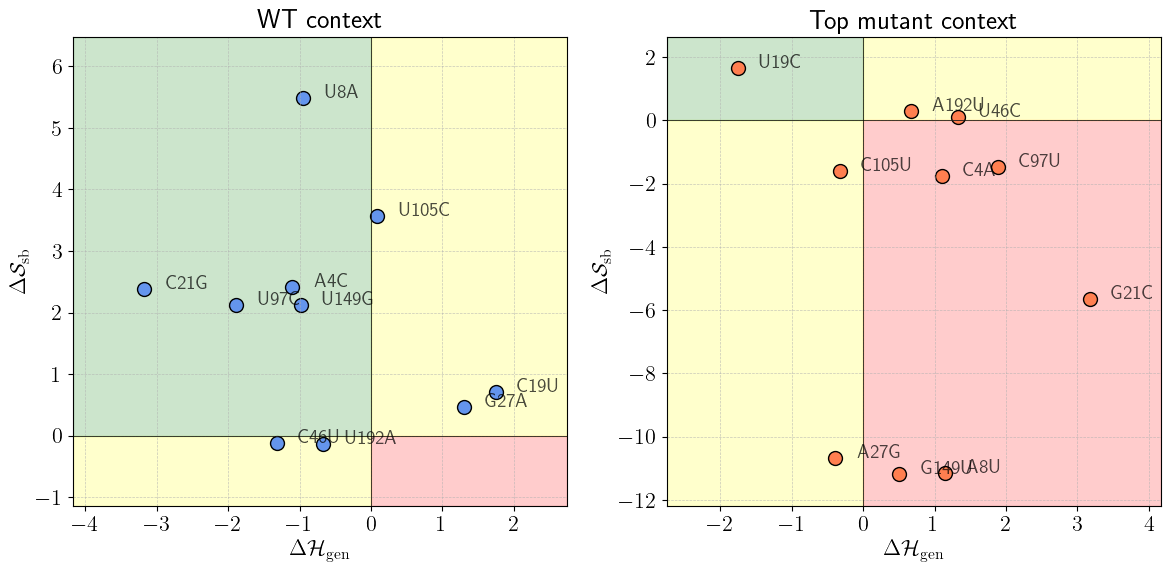

In [65]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6), dpi=100)

# mutations in the context of the wild type sequence
delta_scores = compute_delta_scores(wt_sequence, mutations, params, tokens, fe="sb")
delta_dca = [score["dca"] for score in delta_scores.values()]
delta_sb = [score["sb"] for score in delta_scores.values()]
corr = np.corrcoef(delta_dca, delta_sb)[0, 1]

# Calculate axis limits with padding
x_min, x_max = min(delta_dca) - 1, max(delta_dca) + 1
y_min, y_max = min(delta_sb) - 1, max(delta_sb) + 1

# Set explicit axis limits first
ax[0].set_xlim(x_min, x_max)
ax[0].set_ylim(y_min, y_max)

# Add colored areas for WT context - now they'll extend to the plot borders
# Green: delta_dca < 0 and delta_sb > 0 (upper left quadrant)
ax[0].fill_between([x_min, 0], 0, y_max, color='green', alpha=0.2, label='Favorable')
# Red: delta_dca > 0 and delta_sb < 0 (lower right quadrant)
ax[0].fill_between([0, x_max], y_min, 0, color='red', alpha=0.2, label='Unfavorable')
# Yellow: other quadrants
ax[0].fill_between([0, x_max], 0, y_max, color='yellow', alpha=0.2, label='Other')
ax[0].fill_between([x_min, 0], y_min, 0, color='yellow', alpha=0.2)

ax[0].scatter(delta_dca, delta_sb, color="cornflowerblue", edgecolor="black", s=100)
ax[0].set_xlabel(r"$\Delta \mathcal{H}_{\mathrm{gen}}$")
ax[0].set_ylabel(r"$\Delta \mathcal{S}_{\mathrm{sb}}$")

# put annotation with mutation names
for i, mut in enumerate(delta_scores.keys()):
    ax[0].annotate(mut.replace("_", ""), (delta_dca[i]+0.3, delta_sb[i]), fontsize=14, alpha=0.7)

ax[0].set_title(f"WT context")
ax[0].grid(lw=0.5, ls="--", alpha=0.7)
ax[0].axhline(0, color='black', linewidth=0.5)
ax[0].axvline(0, color='black', linewidth=0.5)

# mutations in the context of the top mutant sequence
delta_scores = compute_delta_scores(top_mutant, mutations_reversed, params, tokens, fe="sb")
delta_dca = [score["dca"] for score in delta_scores.values()]
delta_sb = [score["sb"] for score in delta_scores.values()]
corr = np.corrcoef(delta_dca, delta_sb)[0, 1]

# Calculate axis limits with padding
x_min, x_max = min(delta_dca) - 1, max(delta_dca) + 1
y_min, y_max = min(delta_sb) - 1, max(delta_sb) + 1

# Set explicit axis limits first
ax[1].set_xlim(x_min, x_max)
ax[1].set_ylim(y_min, y_max)

# Add colored areas for top mutant context - now they'll extend to the plot borders
# Green: delta_dca < 0 and delta_sb > 0 (upper left quadrant)
ax[1].fill_between([x_min, 0], 0, y_max, color='green', alpha=0.2, label='Favorable')
# Red: delta_dca > 0 and delta_sb < 0 (lower right quadrant)
ax[1].fill_between([0, x_max], y_min, 0, color='red', alpha=0.2, label='Unfavorable')
# Yellow: other quadrants
ax[1].fill_between([0, x_max], 0, y_max, color='yellow', alpha=0.2, label='Other')
ax[1].fill_between([x_min, 0], y_min, 0, color='yellow', alpha=0.2)

ax[1].scatter(delta_dca, delta_sb, color="coral", edgecolor="black", s=100)
ax[1].set_xlabel(r"$\Delta \mathcal{H}_{\mathrm{gen}}$")
ax[1].set_ylabel(r"$\Delta \mathcal{S}_{\mathrm{sb}}$")

# put annotation with mutation names
for i, mut in enumerate(delta_scores.keys()):
    ax[1].annotate(mut.replace("_", ""), (delta_dca[i]+0.3, delta_sb[i]), fontsize=14, alpha=0.7)
    
ax[1].set_title(f"Top mutant context")
ax[1].grid(lw=0.5, ls="--", alpha=0.7)
ax[1].axhline(0, color='black', linewidth=0.5)
ax[1].axvline(0, color='black', linewidth=0.5)
#ax[0].legend(loc='upper left')

plt.tight_layout()
plt.show()

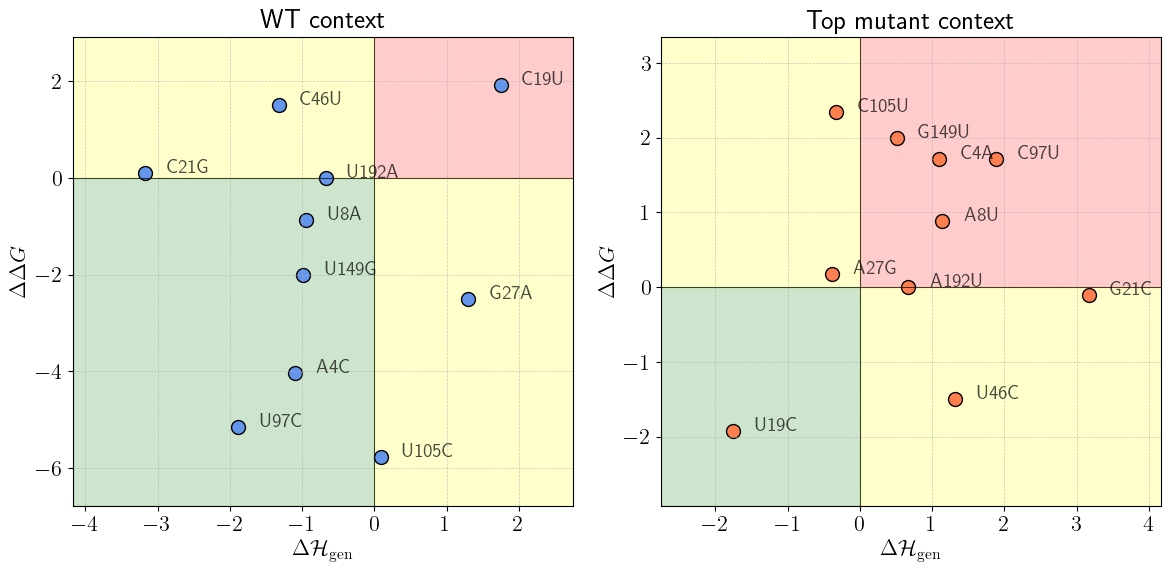

In [66]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6), dpi=100)

# mutations in the context of the wild type sequence
delta_scores = compute_delta_scores(wt_sequence, mutations, params, tokens, fe="fe")
delta_dca = [score["dca"] for score in delta_scores.values()]
delta_fe = [score["sb"] for score in delta_scores.values()]
corr = np.corrcoef(delta_dca, delta_fe)[0, 1]

# Calculate axis limits with padding
x_min, x_max = min(delta_dca) - 1, max(delta_dca) + 1
y_min, y_max = min(delta_fe) - 1, max(delta_fe) + 1

# Set explicit axis limits first
ax[0].set_xlim(x_min, x_max)
ax[0].set_ylim(y_min, y_max)

# Add colored areas for WT context - corrected for free energy
# Green: delta_dca < 0 and delta_fe < 0 (lower left quadrant)
ax[0].fill_between([x_min, 0], y_min, 0, color='green', alpha=0.2, label='Favorable')
# Red: delta_dca > 0 and delta_fe > 0 (upper right quadrant)
ax[0].fill_between([0, x_max], 0, y_max, color='red', alpha=0.2, label='Unfavorable')
# Yellow: other quadrants
ax[0].fill_between([x_min, 0], 0, y_max, color='yellow', alpha=0.2, label='Other')
ax[0].fill_between([0, x_max], y_min, 0, color='yellow', alpha=0.2)

ax[0].scatter(delta_dca, delta_fe, color="cornflowerblue", edgecolor="black", s=100)
ax[0].set_xlabel(r"$\Delta \mathcal{H}_{\mathrm{gen}}$")
ax[0].set_ylabel(r"$\Delta \Delta G$")

# put annotation with mutation names
for i, mut in enumerate(delta_scores.keys()):
    ax[0].annotate(mut.replace("_", ""), (delta_dca[i]+0.3, delta_fe[i]), fontsize=14, alpha=0.7)

ax[0].set_title(f"WT context")
ax[0].grid(lw=0.5, ls="--", alpha=0.7)
ax[0].axhline(0, color='black', linewidth=0.5)
ax[0].axvline(0, color='black', linewidth=0.5)

# mutations in the context of the top mutant sequence
delta_scores = compute_delta_scores(top_mutant, mutations_reversed, params, tokens, fe="fe")
delta_dca = [score["dca"] for score in delta_scores.values()]
delta_fe = [score["sb"] for score in delta_scores.values()]
corr = np.corrcoef(delta_dca, delta_fe)[0, 1]

# Calculate axis limits with padding
x_min, x_max = min(delta_dca) - 1, max(delta_dca) + 1
y_min, y_max = min(delta_fe) - 1, max(delta_fe) + 1

# Set explicit axis limits first
ax[1].set_xlim(x_min, x_max)
ax[1].set_ylim(y_min, y_max)

# Add colored areas for top mutant context - corrected for free energy
# Green: delta_dca < 0 and delta_fe < 0 (lower left quadrant)
ax[1].fill_between([x_min, 0], y_min, 0, color='green', alpha=0.2, label='Favorable')
# Red: delta_dca > 0 and delta_fe > 0 (upper right quadrant)
ax[1].fill_between([0, x_max], 0, y_max, color='red', alpha=0.2, label='Unfavorable')
# Yellow: other quadrants
ax[1].fill_between([x_min, 0], 0, y_max, color='yellow', alpha=0.2, label='Other')
ax[1].fill_between([0, x_max], y_min, 0, color='yellow', alpha=0.2)

ax[1].scatter(delta_dca, delta_fe, color="coral", edgecolor="black", s=100)
ax[1].set_xlabel(r"$\Delta \mathcal{H}_{\mathrm{gen}}$")
ax[1].set_ylabel(r"$\Delta \Delta G$")

# put annotation with mutation names
for i, mut in enumerate(delta_scores.keys()):
    ax[1].annotate(mut.replace("_", ""), (delta_dca[i]+0.3, delta_fe[i]), fontsize=14, alpha=0.7)
    
ax[1].set_title(f"Top mutant context")
ax[1].grid(lw=0.5, ls="--", alpha=0.7)
ax[1].axhline(0, color='black', linewidth=0.5)
ax[1].axvline(0, color='black', linewidth=0.5)

plt.tight_layout()
plt.show()


### Check CDE

In [53]:
import torch
device = torch.device("mps")
dtype = torch.float32

In [54]:
tokens = "ACGU-"
path_model = "../modello_FC_T=1"
params_file = np.load(path_model, allow_pickle=True)

params = {
    "bias": torch.tensor(params_file["h_local"], dtype=dtype, device=device),
    "coupling_matrix": torch.tensor(params_file["couplings"], dtype=dtype, device=device),
}

In [55]:
from typing import Dict

def get_cde(
    sequence: torch.Tensor,
    params: Dict[str, torch.Tensor],
) -> torch.Tensor:
    """Returns the context-dependent entropy (CDE) at each position of the sequence.

    Args:
        sequence (torch.Tensor): One-hot encoded sequence of shape (L, q).
        params (Dict[str, torch.Tensor]): Parameters of the model.
            - "bias": Tensor of shape (L, q) - local biases.
            - "coupling_matrix": Tensor of shape (L, q, L, q) - coupling matrix.
            
    Returns:
        torch.Tensor: Context-dependent entropy (CDE) at each position, shape (L,).
    """
    L, q = sequence.shape
    device = sequence.device
    dtype = sequence.dtype
    cde = torch.zeros(L, device=device, dtype=dtype)
    for idx in range(L):
        couplings_residue = params["coupling_matrix"][idx].reshape(q, L * q)
        logit_residue = params["bias"][idx].unsqueeze(0) + sequence.reshape(L * q) @ couplings_residue.T # (,q)
        probs = torch.softmax(logit_residue, dim=-1)
        cde[idx] = -torch.sum(probs * torch.log(probs + 1e-8)) # CDE at position idx

    return cde

In [56]:
wt_torch = torch.tensor(encoded_wt, dtype=torch.float32, device=device)[3:-1]
wt_torch_oh = torch.nn.functional.one_hot(wt_torch.long(), num_classes=len(tokens)).float()
print(wt_torch_oh.shape)

torch.Size([193, 5])


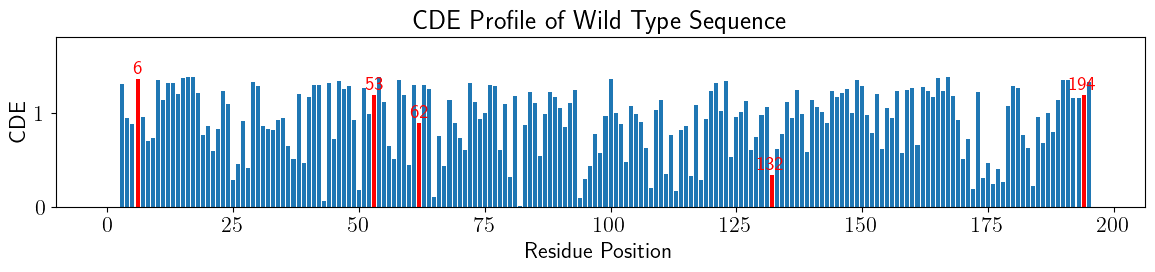

In [57]:
cde_wt = get_cde(wt_torch_oh, params)
# add three sites at the beginning and one at the end with CDE = 0, to account for the fact that we removed them before
cde_wt = torch.cat([torch.zeros(3, device=device), cde_wt, torch.zeros(1, device=device)])
max_cde = -np.log(1/5)

fig, ax = plt.subplots(figsize=(12, 3), dpi=100)
ax.bar(range(len(cde_wt)), cde_wt.cpu().numpy())

# color in red the key positions and add annotations
for pos in positions_above_threshold:
    if 0 <= pos < len(cde_wt):
        ax.bar(pos, cde_wt[pos].cpu().numpy(), color='red')
        ax.text(pos, cde_wt[pos].cpu().numpy() + 0.01, str(pos), ha='center', va='bottom', fontsize=14, color='red')
ax.set_xlabel("Residue Position")
ax.set_ylabel("CDE")
ax.set_title("CDE Profile of Wild Type Sequence")
ax.set_ylim(0, max_cde + 0.2)
plt.tight_layout()
plt.show()

In [287]:
# save cde values for the wild type sequence in a text file
with open(f"cde_values_{wild_type_id}.txt", "w") as f:
    for cde_value in cde_wt.cpu().numpy():
        f.write(f"{cde_value} ")

### Count G-C content and Watson-Crick pairs

In [108]:
def count_rna_base_pairs(sequence, dot_bracket):
    """
    Computes both the G-C count and the total Watson-Crick (G-C + A-U) count 
    for an RNA sequence given its dot-bracket structure.
    """
    if len(sequence) != len(dot_bracket):
        raise ValueError("The sequence and dot-bracket structure must be the same length.")

    stack = []
    gc_count = 0
    wc_count = 0
    n_contacts = 0
    
    # Optional: Keep track of pairs for debugging/verification
    pair_details = [] 

    for i, char in enumerate(dot_bracket):
        if char == '(':
            stack.append(i)
        elif char == ')':
            if not stack:
                raise ValueError("Invalid structure: too many closing brackets.")
            
            # Match found
            j = stack.pop()
            n_contacts += 1
            
            # Extract the bases and create a set for easy comparison
            b1 = sequence[j].upper()
            b2 = sequence[i].upper()
            pair_set = {b1, b2}
            
            # Check for G-C pair
            if pair_set == {'G', 'C'}:
                gc_count += 1
                wc_count += 1
                pair_details.append((j, i, f"{b1}-{b2}", "G-C"))
            
            # Check for A-U pair
            elif pair_set == {'A', 'U'}:
                wc_count += 1
                pair_details.append((j, i, f"{b1}-{b2}", "A-U"))

    if stack:
        raise ValueError("Invalid structure: too many opening brackets.")

    # Return a dictionary with the results
    return {
        "G-C count": gc_count,
        "Watson-Crick count": wc_count,
        "Detailed pairs": pair_details,
        "Total contacts": n_contacts,
    }

In [52]:
wt_props = count_rna_base_pairs(wt_sequence, structure)
mutants_props = {
    "G-C count": [],
    "Watson-Crick count": [],
    "Total contacts": [],
}

for idx, row in top_mutants.iterrows():
    mutant_seq = row["seq"]
    mutant_props = count_rna_base_pairs(mutant_seq, structure)
    mutants_props["G-C count"].append(mutant_props["G-C count"])
    mutants_props["Watson-Crick count"].append(mutant_props["Watson-Crick count"])
    mutants_props["Total contacts"].append(mutant_props["Total contacts"])


In [109]:
def summary_stats(df_mutants, region, wt_id, n_top):
    df_wt = df_mutants[(df_mutants["region"] == region) & (df_mutants["wt_id"] == float(wt_id))]
    print(f"Number of mutants in region '{region}' for WT '{wt_id}': {len(df_wt)}")
    
    top_mutants = df_wt.sort_values(by="activity_60", ascending=False).head(n_top)
    mutants_props = {
        "G-C count": [],
        "Watson-Crick count": [],
        "Total contacts": [],
    }

    for idx, row in top_mutants.iterrows():
        mutant_seq = row["seq"]
        mutant_props = count_rna_base_pairs(mutant_seq, structure)
        mutants_props["G-C count"].append(mutant_props["G-C count"])
        mutants_props["Watson-Crick count"].append(mutant_props["Watson-Crick count"])
        mutants_props["Total contacts"].append(mutant_props["Total contacts"])

    gc_count_mean = np.mean(mutants_props["G-C count"])
    gc_count_std = np.std(mutants_props["G-C count"])
    wc_count_mean = np.mean(mutants_props["Watson-Crick count"])
    wc_count_std = np.std(mutants_props["Watson-Crick count"])
    
    return {
        "G-C count": (gc_count_mean, gc_count_std),
        "Watson-Crick count": (wc_count_mean, wc_count_std),
    }

In [60]:
wild_type_id = "wt_1"
region = "lowDCA_highSB"
n_top = 10

old_wt_name = df_wt_summary[df_wt_summary["WT name"] == wild_type_id]["old name"].values[0]
wt_sequence = df_matching_data[df_matching_data["names"] == old_wt_name]["sequences"].values[0]
df_wt = df_mutants[(df_mutants["region"] == region) & (df_mutants["wt_id"] == float(wild_type_id.split("_")[1]))]

In [61]:
summary_wt = count_rna_base_pairs(wt_sequence, structure)
summary_mutants = summary_stats(df_mutants, region, wild_type_id.split("_")[1], n_top)

print(f"Wild type properties: {summary_wt}")
print(f"Mutants properties (mean ± std): {summary_mutants}")

Number of mutants in region 'lowDCA_highSB' for WT '1': 150
Wild type properties: {'G-C count': 32, 'Watson-Crick count': 40, 'Detailed pairs': [(13, 18, 'G-C', 'G-C'), (12, 19, 'G-C', 'G-C'), (8, 22, 'C-G', 'G-C'), (6, 24, 'U-A', 'A-U'), (5, 25, 'U-A', 'A-U'), (3, 27, 'C-G', 'G-C'), (60, 65, 'C-G', 'G-C'), (59, 66, 'A-U', 'A-U'), (58, 67, 'C-G', 'G-C'), (56, 69, 'C-G', 'G-C'), (51, 73, 'C-G', 'G-C'), (50, 74, 'C-G', 'G-C'), (46, 78, 'G-C', 'G-C'), (44, 80, 'G-C', 'G-C'), (43, 81, 'G-C', 'G-C'), (42, 82, 'C-G', 'G-C'), (41, 83, 'U-A', 'A-U'), (96, 103, 'C-G', 'G-C'), (95, 104, 'G-C', 'G-C'), (94, 105, 'G-C', 'G-C'), (93, 106, 'C-G', 'G-C'), (90, 109, 'C-G', 'G-C'), (86, 112, 'C-G', 'G-C'), (85, 113, 'C-G', 'G-C'), (120, 132, 'G-C', 'G-C'), (118, 133, 'G-C', 'G-C'), (143, 148, 'C-G', 'G-C'), (142, 149, 'G-C', 'G-C'), (137, 153, 'C-G', 'G-C'), (136, 154, 'C-G', 'G-C'), (135, 155, 'A-U', 'A-U'), (134, 156, 'C-G', 'G-C'), (35, 164, 'U-A', 'A-U'), (32, 167, 'G-C', 'G-C'), (31, 168, 'G-C', '

In [112]:
n_top = 50
df_results = pd.DataFrame()
for wt_id in [f"wt_{i}" for i in range(1, 11)]:
    for region in ["lowDCA_lowSB", "lowDCA_highSB", "highDCA_highSB"]:
        old_wt_name = df_wt_summary[df_wt_summary["WT name"] == wt_id]["old name"].values[0]
        wt_sequence = df_matching_data[df_matching_data["names"] == old_wt_name]["sequences"].values[0]
        wt_stats = count_rna_base_pairs(wt_sequence, structure)
        summary_mutants = summary_stats(df_mutants, region, wt_id.split("_")[1], n_top)
        df_partial = pd.DataFrame({
            "WT ID": wt_id,
            "Region": region,
            "n_top": n_top,
            "WT G-C count": wt_stats["G-C count"],
            "WT Watson-Crick count": wt_stats["Watson-Crick count"],
            "Mutants G-C count (mean)": summary_mutants["G-C count"][0],
            "Mutants G-C count (std)": summary_mutants["G-C count"][1],
            "Mutants Watson-Crick count (mean)": summary_mutants["Watson-Crick count"][0],
            "Mutants Watson-Crick count (std)": summary_mutants["Watson-Crick count"][1],
        }, index=[0])
        df_results = pd.concat([df_results, df_partial], ignore_index=True)

Number of mutants in region 'lowDCA_lowSB' for WT '1': 50
Number of mutants in region 'lowDCA_highSB' for WT '1': 150
Number of mutants in region 'highDCA_highSB' for WT '1': 50
Number of mutants in region 'lowDCA_lowSB' for WT '2': 50
Number of mutants in region 'lowDCA_highSB' for WT '2': 150
Number of mutants in region 'highDCA_highSB' for WT '2': 50
Number of mutants in region 'lowDCA_lowSB' for WT '3': 50
Number of mutants in region 'lowDCA_highSB' for WT '3': 150
Number of mutants in region 'highDCA_highSB' for WT '3': 50
Number of mutants in region 'lowDCA_lowSB' for WT '4': 50
Number of mutants in region 'lowDCA_highSB' for WT '4': 150
Number of mutants in region 'highDCA_highSB' for WT '4': 50
Number of mutants in region 'lowDCA_lowSB' for WT '5': 50
Number of mutants in region 'lowDCA_highSB' for WT '5': 150
Number of mutants in region 'highDCA_highSB' for WT '5': 50
Number of mutants in region 'lowDCA_lowSB' for WT '6': 50
Number of mutants in region 'lowDCA_highSB' for WT '

In [113]:
df_results.head(10)

,WT ID,Region,n_top,WT G-C count,WT Watson-Crick count,Mutants G-C count (mean),Mutants G-C count (std),Mutants Watson-Crick count (mean),Mutants Watson-Crick count (std)
0,wt_1,lowDCA_lowSB,50,32,40,31.90,1.187434,40.96,1.310878
1,wt_1,lowDCA_highSB,50,32,40,33.26,1.145600,44.34,1.142103
2,wt_1,highDCA_highSB,50,32,40,31.56,1.202664,40.24,1.490772
3,wt_2,lowDCA_lowSB,50,32,41,31.72,0.938936,41.14,1.149087
4,wt_2,lowDCA_highSB,50,32,41,33.40,1.000000,43.90,1.187434
5,wt_2,highDCA_highSB,50,32,41,31.82,1.125877,40.70,1.640122
6,wt_3,lowDCA_lowSB,50,31,43,29.98,1.303687,41.78,1.153950
7,wt_3,lowDCA_highSB,50,31,43,32.64,0.714423,45.18,0.993781
8,wt_3,highDCA_highSB,50,31,43,30.76,0.970773,42.52,1.299846
9,wt_4,lowDCA_lowSB,50,30,41,29.90,0.921954,41.08,1.128539


In [114]:
df_results.to_csv("../mutation_summary_results.csv", index=False)

Wild types mutual distances

In [120]:
wild_type_sequences = []
for wt_id in [f"wt_{i}" for i in range(1, 11)]:
    old_wt_name = df_wt_summary[df_wt_summary["WT name"] == wt_id]["old name"].values[0]
    wt_sequence = df_matching_data[df_matching_data["names"] == old_wt_name]["sequences"].values[0]
    wild_type_sequences.append(wt_sequence)

In [121]:
wild_type_sequences_enc = encode_sequence(wild_type_sequences, tokens)

def get_distance(s1, s2):
    return np.sum(s1 != s2)

distance_matrix = np.zeros((len(wild_type_sequences_enc), len(wild_type_sequences_enc)), dtype=int)
for i in range(len(wild_type_sequences_enc)):
    for j in range(i + 1, len(wild_type_sequences_enc)):
        dist = get_distance(wild_type_sequences_enc[i], wild_type_sequences_enc[j])
        distance_matrix[i, j] = dist
        distance_matrix[j, i] = dist

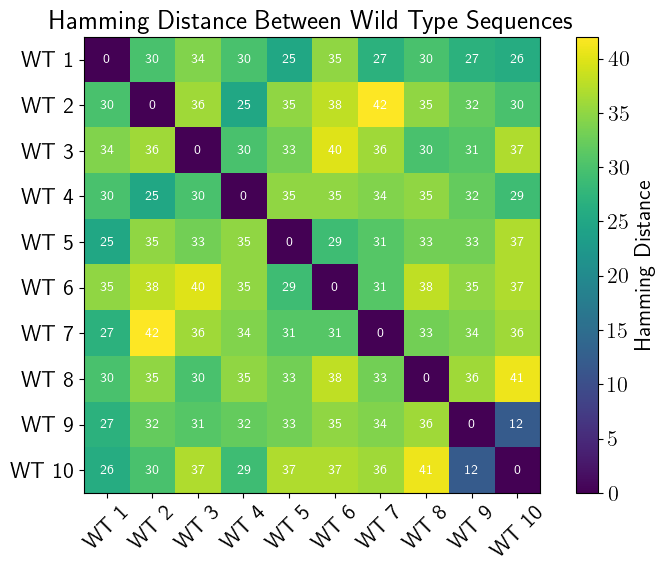

In [123]:
# show distance matrix as a heatmap with annotations
plt.figure(figsize=(8, 6), dpi=100)
plt.imshow(distance_matrix, cmap="viridis", vmin=0, vmax=np.max(distance_matrix))
plt.colorbar(label="Hamming Distance")
plt.xticks(range(len(wild_type_sequences)), [f"WT {i+1}" for i in range(len(wild_type_sequences))], rotation=45)
plt.yticks(range(len(wild_type_sequences)), [f"WT {i+1}" for i in range(len(wild_type_sequences))])
plt.title("Hamming Distance Between Wild Type Sequences")

# Add text annotations for each cell
for i in range(len(distance_matrix)):
    for j in range(len(distance_matrix)):
        plt.text(j, i, str(distance_matrix[i, j]), 
                ha='center', va='center', color='white', fontsize=10)

plt.tight_layout()
plt.show()